**Name:** Priyank Sarohi  
**Adm No:** 2026B15310032

# Healthcare Readmission & Patient Flow

**Project 07 | Dataset: UCI Diabetes 130-US Hospitals (1999-2008)**


## 1. Import libraries

In [5]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

## 2. Upload and load dataset

In [6]:
up = files.upload()

# unzip uploaded zip files
for name in up:
    if name.endswith('.zip'):
        with zipfile.ZipFile(name) as z:
            z.extractall('data')

# find diabetic_data.csv
path = None
for folder, sub, fl in os.walk('.'):
    for f in fl:
        if f.startswith('diabetic_data') and f.endswith('.csv'):
            path = os.path.join(folder, f)

if path is None:
    print('Error: diabetic_data.csv not found. Run this cell again and upload the CSV or ZIP file.')
else:
    df = pd.read_csv(path)
    print('Loaded:', path)
    # ID columns hidden for privacy
    display(df.drop(columns=['encounter_id', 'patient_nbr']).head())

Saving diabetic_data.csv to diabetic_data.csv
Loaded: ./diabetic_data.csv


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),?,1,1,7,3,?,?,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,...,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),?,1,1,7,2,?,?,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),?,1,1,7,1,?,?,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. Dataset inspection

In [7]:
print(df.shape)
df.info()
display(df.describe())

(101766, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


## 4. Check missing values

In [8]:
# this dataset writes missing values as '?'
q = (df == '?').sum()
q = q[q > 0]
print(q)

# change '?' to NaN so isnull() can find them (no column is dropped)
df = df.replace('?', np.nan)

miss = df.isnull().sum()
miss = miss[miss > 0]
pct = (miss / len(df) * 100).round(1)
print(pct.sort_values(ascending=False))

race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
dtype: int64
weight               96.9
max_glu_serum        94.7
A1Cresult            83.3
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0
dtype: float64


## 5. Check duplicate records

In [10]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate encounter_id:', df['encounter_id'].duplicated().sum())

# exact copies add no new information, so remove them
df = df.drop_duplicates()
print('Rows now:', len(df))

Duplicate rows: 0
Duplicate encounter_id: 0
Rows now: 101766


## 6. Validate patient_nbr and encounter_id

In [11]:
print(df[['encounter_id', 'patient_nbr']].isnull().sum())
print('encounter_id unique:', df['encounter_id'].is_unique)
print('Encounters:', len(df))
print('Unique patients:', df['patient_nbr'].nunique())

cnt = df['patient_nbr'].value_counts()
print('Patients with more than 1 encounter:', (cnt > 1).sum())

encounter_id    0
patient_nbr     0
dtype: int64
encounter_id unique: True
Encounters: 101766
Unique patients: 71518
Patients with more than 1 encounter: 16773


## 7. Data types and categorical columns

In [12]:
print(df.dtypes.value_counts())

cat = df.select_dtypes(exclude='number').columns
print(list(cat))

# numeric codes that are really categories
codes = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
print(df[codes].nunique())

for c in ['gender', 'age', 'readmitted']:
    print(df[c].value_counts())

object    37
int64     13
Name: count, dtype: int64
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']
admission_type_id            8
discharge_disposition_id    26
admission_source_id         17
dtype: int64
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)       

## 8. Average and median hospital stay

In [13]:
stay = df['time_in_hospital']
print('Mean:', round(stay.mean(), 2))
print('Median:', stay.median())
print('Min and max:', stay.min(), stay.max())

Mean: 4.4
Median: 4.0
Min and max: 1 14


## 9. Length-of-stay quantiles (with NumPy)

In [14]:
print(stay.quantile([0.25, 0.5, 0.75, 0.9, 0.95]))

# NumPy operations
arr = np.array(df['time_in_hospital'])          # create array
print(arr[:10])                                  # slicing
print(arr.mean(), np.median(arr))                # mean, median
print(np.percentile(arr, [25, 50, 75, 90]))      # percentiles

long_arr = arr[arr >= 7]                         # boolean filtering
print('Stays of 7+ days (%):', round(len(long_arr) / len(arr) * 100, 1))

hours = arr * 24                                 # vectorised calculation
print('Mean stay in hours:', round(hours.mean(), 1))

df['stay_type'] = np.where(arr >= 7, 'long', 'short')

0.25     2.0
0.50     4.0
0.75     6.0
0.90     9.0
0.95    11.0
Name: time_in_hospital, dtype: float64
[ 1  3  2  2  1  3  4  5 13 12]
4.395986871843248 4.0
[2. 4. 6. 9.]
Stays of 7+ days (%): 20.8
Mean stay in hours: 105.5


In [ ]:
# NumPy bootstrap: uncertainty of the mean stay
np.random.seed(1)
means = []
for i in range(1000):
    s = np.random.choice(arr, size=len(arr), replace=True)
    means.append(s.mean())

print('95% range of mean stay:', np.percentile(means, [2.5, 97.5]).round(3))

## 10. Patient visit frequency

In [15]:
visits = df.groupby('patient_nbr').size()
print(visits.describe())
print(visits.value_counts().sort_index().head(10))
print('Patients with only 1 encounter (%):', round((visits == 1).mean() * 100, 1))

# add visit count to each row and make groups
df['visits'] = df['patient_nbr'].map(visits)
df['visit_grp'] = pd.cut(df['visits'], bins=[0, 1, 3, 1000],
                         labels=['1 visit', '2-3 visits', '4+ visits']).astype(str)
print(df['visit_grp'].value_counts())

count    71518.000000
mean         1.422942
std          1.090740
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
dtype: float64
1     54745
2     10434
3      3328
4      1421
5       717
6       346
7       207
8       111
9        70
10       42
Name: count, dtype: int64
Patients with only 1 encounter (%): 76.5
visit_grp
1 visit       54745
2-3 visits    30852
4+ visits     16169
Name: count, dtype: int64


## 11. Readmission categories

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     53.9
>30    34.9
<30    11.2
Name: count, dtype: float64


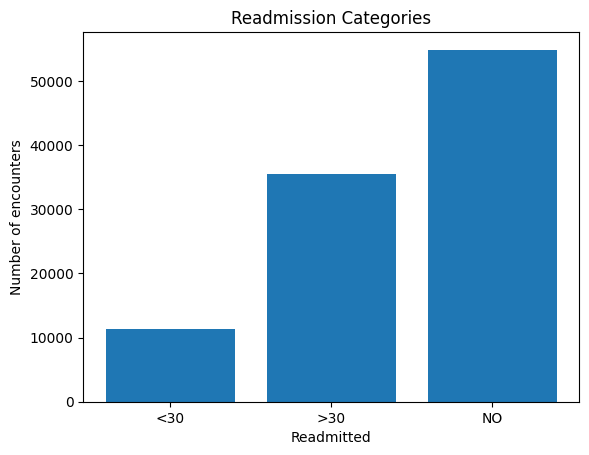

In [16]:
rd = df['readmitted'].value_counts()
print(rd)
print((rd / len(df) * 100).round(1))

# flags: 1 = yes, 0 = no
df['r30'] = (df['readmitted'] == '<30').astype(int)
df['any_re'] = (df['readmitted'] != 'NO').astype(int)

rd = rd.reindex(['<30', '>30', 'NO'])
plt.bar(rd.index, rd.values)
plt.title('Readmission Categories')
plt.xlabel('Readmitted')
plt.ylabel('Number of encounters')
plt.show()

## 12. Readmission and stay by age group

readmitted   <30   >30    NO
age                         
[0-10)       1.9  16.1  82.0
[10-20)      5.8  32.4  61.8
[20-30)     14.2  30.8  55.0
[30-40)     11.2  31.4  57.3
[40-50)     10.6  33.8  55.5
[50-60)      9.7  34.3  56.0
[60-70)     11.1  35.1  53.7
[70-80)     11.8  36.3  51.9
[80-90)     12.1  36.2  51.7
[90-100)    11.1  28.9  60.0
          count  mean  median
age                          
[0-10)      161  2.55     2.0
[10-20)     691  3.19     2.0
[20-30)    1657  3.56     3.0
[30-40)    3775  3.80     3.0
[40-50)    9685  4.04     3.0
[50-60)   17256  4.13     3.0
[60-70)   22483  4.38     4.0
[70-80)   26068  4.59     4.0
[80-90)   17197  4.81     4.0
[90-100)   2793  4.76     4.0


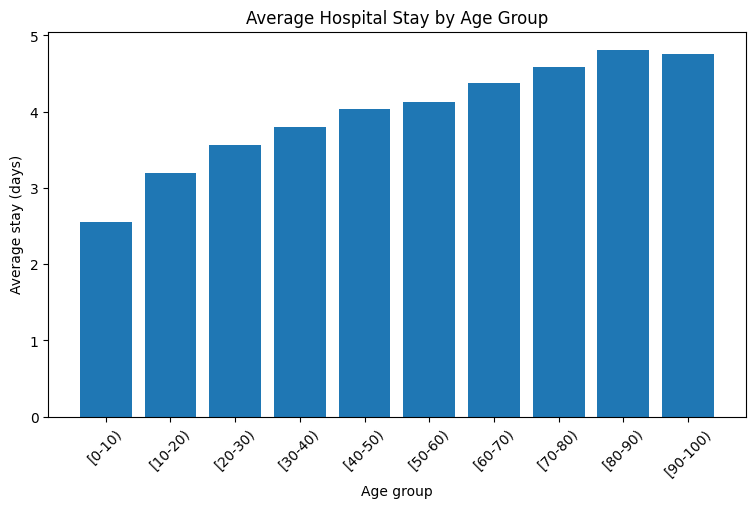

In [17]:
age_tab = pd.crosstab(df['age'], df['readmitted'], normalize='index') * 100
print(age_tab.round(1))

age_los = df.groupby('age')['time_in_hospital'].agg(['count', 'mean', 'median']).round(2)
print(age_los)

plt.figure(figsize=(9, 5))
plt.bar(age_los.index, age_los['mean'])
plt.title('Average Hospital Stay by Age Group')
plt.xlabel('Age group')
plt.ylabel('Average stay (days)')
plt.xticks(rotation=45)
plt.show()

## 13. Hospital stay by gender

Rows left out: 3
        count  mean  median
gender                     
Female  54708  4.48     4.0
Male    47055  4.30     3.0


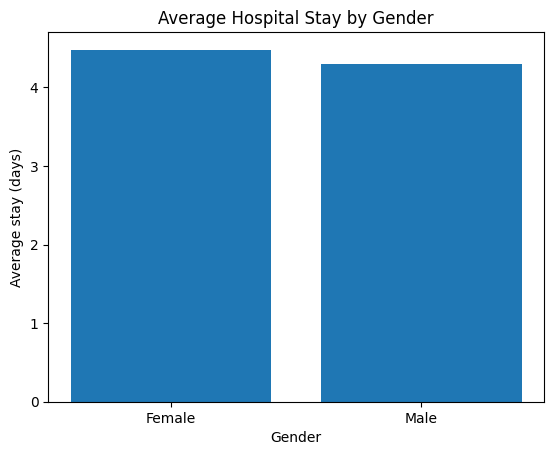

In [18]:
# only Male and Female are compared (other value has very few rows)
d = df[df['gender'].isin(['Male', 'Female'])]
print('Rows left out:', len(df) - len(d))

g = d.groupby('gender')['time_in_hospital'].agg(['count', 'mean', 'median']).round(2)
print(g)

plt.bar(g.index, g['mean'])
plt.title('Average Hospital Stay by Gender')
plt.xlabel('Gender')
plt.ylabel('Average stay (days)')
plt.show()

## 14. Hospital stay by medical specialty

                            count  mean
medical_specialty                      
Radiologist                  1140  3.48
Cardiology                   5352  3.53
Orthopedics-Reconstructive   1233  3.92
Orthopedics                  1400  3.98
Family/GeneralPractice       7440  4.36
Emergency/Trauma             7565  4.36
Surgery-General              3099  4.55
InternalMedicine            14635  4.58
Nephrology                   1613  5.02
Pulmonology                   871  5.24


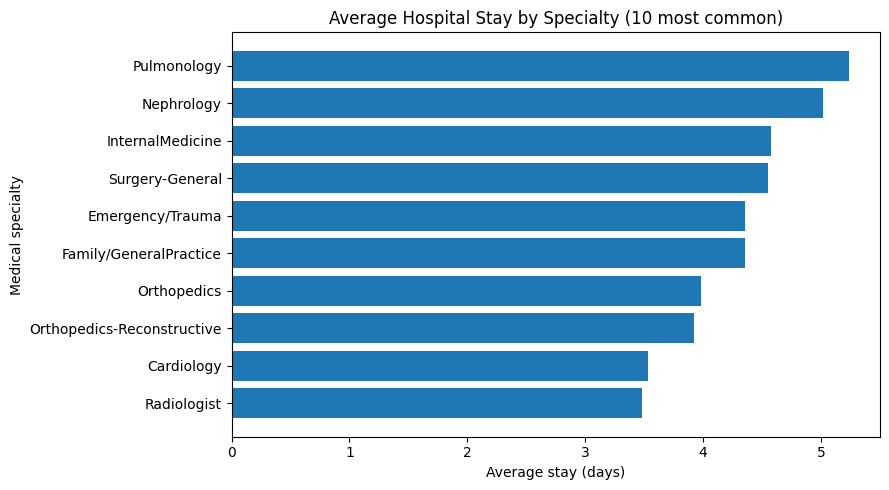

In [19]:
# specialty is missing for many rows, so only known values are used
sp = df[df['medical_specialty'].notnull()]

# keep the 10 most common specialties (small groups are unreliable)
top = sp['medical_specialty'].value_counts().head(10).index
sp = sp[sp['medical_specialty'].isin(top)]

s = sp.groupby('medical_specialty')['time_in_hospital'].agg(['count', 'mean']).round(2)
s = s.sort_values('mean')
print(s)

plt.figure(figsize=(9, 5))
plt.barh(s.index, s['mean'])
plt.title('Average Hospital Stay by Specialty (10 most common)')
plt.xlabel('Average stay (days)')
plt.ylabel('Medical specialty')
plt.tight_layout()
plt.show()

## 15. Pivot tables and cross-tabulations

In [20]:
p1 = pd.pivot_table(d, values='time_in_hospital', index='age',
                    columns='gender', aggfunc='mean')
print(p1.round(2))

p2 = pd.pivot_table(d, values='r30', index='age',
                    columns='gender', aggfunc='mean') * 100
print(p2.round(1))

gender    Female  Male
age                   
[0-10)      2.66  2.42
[10-20)     3.00  3.46
[20-30)     3.56  3.58
[30-40)     3.78  3.83
[40-50)     4.08  4.00
[50-60)     4.19  4.07
[60-70)     4.47  4.29
[70-80)     4.69  4.48
[80-90)     4.88  4.70
[90-100)    4.78  4.71
gender    Female  Male
age                   
[0-10)       1.2   2.6
[10-20)      6.0   5.5
[20-30)     15.9  10.9
[30-40)     11.2  11.3
[40-50)     10.6  10.6
[50-60)      9.9   9.4
[60-70)     10.9  11.3
[70-80)     11.7  11.9
[80-90)     12.2  11.9
[90-100)    11.1  11.0


In [ ]:
print(pd.crosstab(d['gender'], d['readmitted']))
print(pd.crosstab(df['visit_grp'], df['readmitted'], normalize='index').mul(100).round(1))

## 16. Missing-data and category-coding patterns

In [21]:
# is <30 readmission different where a value is missing?
for c in ['medical_specialty', 'payer_code', 'race', 'weight']:
    m = df[c].isnull()
    r1 = round(df.loc[m, 'r30'].mean() * 100, 1)
    r2 = round(df.loc[~m, 'r30'].mean() * 100, 1)
    print(c, '| missing rows:', m.sum(), '| <30 rate missing:', r1, '| present:', r2)

medical_specialty | missing rows: 49949 | <30 rate missing: 11.6 | present: 10.8
payer_code | missing rows: 40256 | <30 rate missing: 11.5 | present: 10.9
race | missing rows: 2273 | <30 rate missing: 8.3 | present: 11.2
weight | missing rows: 98569 | <30 rate missing: 11.2 | present: 11.2


In [22]:
print(df['admission_type_id'].value_counts())
print(df['discharge_disposition_id'].value_counts().head(10))

# codes for death / hospice discharge (check IDs_mapping.csv)
end_codes = [11, 13, 14, 19, 20, 21]
e = df['discharge_disposition_id'].isin(end_codes)
print('Death/hospice codes:', e.sum())
print('<30 rate, those:', round(df.loc[e, 'r30'].mean() * 100, 1))
print('<30 rate, others:', round(df.loc[~e, 'r30'].mean() * 100, 1))

admission_type_id
1    53990
3    18869
2    18480
6     5291
5     4785
8      320
7       21
4       10
Name: count, dtype: int64
discharge_disposition_id
1     60234
3     13954
6     12902
18     3691
2      2128
22     1993
11     1642
5      1184
25      989
4       815
Name: count, dtype: int64
Death/hospice codes: 2423
<30 rate, those: 1.8
<30 rate, others: 11.4


## 17. Descriptive group-level comparisons

In [23]:
# share of encounters readmitted within 30 days (descriptive only)
base = round(df['r30'].mean() * 100, 1)
print('Overall <30 rate (%):', base)

df['inp_grp'] = pd.cut(df['number_inpatient'], bins=[-1, 0, 1, 1000],
                       labels=['0', '1', '2+']).astype(str)

for c in ['age', 'gender', 'visit_grp', 'inp_grp', 'stay_type']:
    t = df.groupby(c)['r30'].agg(['count', 'mean'])
    t['rate_pct'] = (t['mean'] * 100).round(1)
    t['diff_overall'] = (t['rate_pct'] - base).round(1)
    print(t[['count', 'rate_pct', 'diff_overall']])

t = sp.groupby('medical_specialty')['r30'].agg(['count', 'mean'])
t['rate_pct'] = (t['mean'] * 100).round(1)
t['diff_overall'] = (t['rate_pct'] - base).round(1)
print(t[['count', 'rate_pct', 'diff_overall']])

Overall <30 rate (%): 11.2
          count  rate_pct  diff_overall
age                                    
[0-10)      161       1.9          -9.3
[10-20)     691       5.8          -5.4
[20-30)    1657      14.2           3.0
[30-40)    3775      11.2           0.0
[40-50)    9685      10.6          -0.6
[50-60)   17256       9.7          -1.5
[60-70)   22483      11.1          -0.1
[70-80)   26068      11.8           0.6
[80-90)   17197      12.1           0.9
[90-100)   2793      11.1          -0.1
                 count  rate_pct  diff_overall
gender                                        
Female           54708      11.2           0.0
Male             47055      11.1          -0.1
Unknown/Invalid      3       0.0         -11.2
            count  rate_pct  diff_overall
visit_grp                                
1 visit     54745       4.0          -7.2
2-3 visits  30852      16.3           5.1
4+ visits   16169      25.7          14.5
         count  rate_pct  diff_overall
inp_grp  

## 18. Final findings

In [24]:
n = len(df)
pts = df['patient_nbr'].nunique()
multi = round((visits > 1).mean() * 100, 1)
mean_stay = round(df['time_in_hospital'].mean(), 2)
med_stay = df['time_in_hospital'].median()

rp = (df['readmitted'].value_counts() / n * 100).round(1)
r_lt = rp['<30']
r_gt = rp['>30']
r_no = rp['NO']

# age groups with at least 500 encounters
a = df.groupby('age')['r30'].agg(['count', 'mean'])
a = a[a['count'] >= 500]
a_hi = a['mean'].idxmax()
a_lo = a['mean'].idxmin()
a_hi_v = round(a.loc[a_hi, 'mean'] * 100, 1)
a_lo_v = round(a.loc[a_lo, 'mean'] * 100, 1)

gm = d.groupby('gender')['time_in_hospital'].mean().round(2)
g_f = gm['Female']
g_m = gm['Male']
g_word = 'longer' if g_f > g_m else 'shorter'

sm = sp.groupby('medical_specialty')['time_in_hospital'].mean().round(2)
sp_hi = sm.idxmax()
sp_lo = sm.idxmin()
sp_hi_v = sm[sp_hi]
sp_lo_v = sm[sp_lo]

ir = (df.groupby('inp_grp')['r30'].mean() * 100).round(1)
i0 = ir['0']
i2 = ir['2+']

miss_sp = round(df['medical_specialty'].isnull().mean() * 100, 1)

g_diff = round(abs(g_f - g_m), 2)

x = round(df.loc[e, 'r30'].mean() * 100, 1)
y = round(df.loc[~e, 'r30'].mean() * 100, 1)

vr = (df.groupby('visit_grp')['r30'].mean() * 100).round(1)
v1 = vr['1 visit']
v4 = vr['4+ visits']

print(f'1. The data has {n} encounters from {pts} patients. {multi}% of patients have more than one encounter.')
print(f'2. The average stay is {mean_stay} days and the median is {med_stay} days.')
print(f'3. Readmission: within 30 days = {r_lt}%, after 30 days = {r_gt}%, not readmitted = {r_no}%.')
print(f'4. Among age groups with 500+ encounters, the <30 rate is highest for {a_hi} ({a_hi_v}%) and lowest for {a_lo} ({a_lo_v}%).')
print(f'5. Average stay is {g_f} days for females and {g_m} days for males. Females stay {g_word} by {g_diff} days.')
print(f'6. Among the 10 most common specialties, the longest average stay is {sp_hi} ({sp_hi_v} days) and the shortest is {sp_lo} ({sp_lo_v} days).')
print(f'7. The <30 rate is {i0}% with 0 inpatient visits in the previous year and {i2}% with 2 or more.')
print(f'8. {miss_sp}% of medical_specialty values are missing, so specialty results use known values only.')
print(f'9. Encounters with death/hospice discharge codes have a <30 rate of {x}%, compared with {y}% for all other encounters.')
print(f'10. The <30 rate is {v1}% for patients with 1 encounter and {v4}% for patients with 4+ encounters. This is partly because a readmission needs a later encounter in the data.')

1. The data has 101766 encounters from 71518 patients. 23.5% of patients have more than one encounter.
2. The average stay is 4.4 days and the median is 4.0 days.
3. Readmission: within 30 days = 11.2%, after 30 days = 34.9%, not readmitted = 53.9%.
4. Among age groups with 500+ encounters, the <30 rate is highest for [20-30) (14.2%) and lowest for [10-20) (5.8%).
5. Average stay is 4.48 days for females and 4.3 days for males. Females stay longer by 0.18 days.
6. Among the 10 most common specialties, the longest average stay is Pulmonology (5.24 days) and the shortest is Radiologist (3.48 days).
7. The <30 rate is 8.4% with 0 inpatient visits in the previous year and 21.4% with 2 or more.
8. 49.1% of medical_specialty values are missing, so specialty results use known values only.
9. Encounters with death/hospice discharge codes have a <30 rate of 1.8%, compared with 11.4% for all other encounters.
10. The <30 rate is 4.0% for patients with 1 encounter and 25.7% for patients with 4+ e

## Conclusion

The notebook describes how long patients stay, how often they come back and how readmission categories differ across age groups, gender and specialties. The differences shown are descriptive. They do not prove causes.


